# 08 — Tabela geral e figuras do artigo

**Trabalho final — Tópicos Especiais em ESSC II (IA aplicada a Séries Temporais)**

Este notebook **não treina nada**: ele lê os resultados gravados pelos notebooks 02 a 07 e 09 (pasta `resultados/`) e monta:

1. a **tabela geral comparativa** de todas as arquiteturas (item 4 do enunciado);
2. o **resumo do estudo de ablação** (as 5 variantes de pré-processamento, em 4 modelos);
3. as **figuras no formato do artigo** (300 dpi), em `figuras/08_*.png`;
4. as tabelas em **LaTeX** (`resultados/08_*.tex`), prontas para o modelo da SBC.

Todos os números são **F1 macro no teste**, com **sinalizantes nunca vistos no treino**: média ± desvio padrão de 4 rodadas × 3 sementes (12 avaliações; 4 para os modelos determinísticos).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

BASE = Path.cwd().parent if (Path.cwd().parent / "resultados").exists() else Path.cwd()
RES, FIG = BASE / "resultados", BASE / "figuras"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

def ler(nome):
    return pd.read_csv(RES / nome)

def resumo(v):
    return f"{100 * v.mean():.1f} ± {100 * (v.std() if len(v) > 1 else 0):.1f}"

r02, r03 = ler("02_resultados_por_rodada.csv"), ler("03_resultados_por_rodada.csv")
r04, r05 = ler("04_ablacao_por_rodada.csv"), ler("05_horizonte_por_rodada.csv")
r06c, r06d = ler("06_calibrado_teste.csv"), ler("06_diferencas_por_rodada.csv")
r07 = ler("07_bonus_por_rodada.csv")
r09a, r09b = ler("09_cnns_por_rodada.csv"), ler("09_aumento_por_rodada.csv")
print("resultados lidos:", {n: len(d) for n, d in [("02", r02), ("03", r03), ("04", r04), ("05", r05), ("06 calibração", r06c),
                                                   ("06 diferenças", r06d), ("07", r07),
                                                   ("09 CNNs", r09a), ("09 aumento", r09b)]})

resultados lidos: {'02': 80, '03': 72, '04': 192, '05': 768, '06 calibração': 72, '06 diferenças': 144, '07': 36, '09 CNNs': 48, '09 aumento': 60}


## 1. Tabela geral comparativa

- **Grupos** como no enunciado (2.3-A a 2.3-E) mais as baselines.
- **Original:** a configuração dos notebooks 02 e 03. **Calibrada:** a escolhida na validação no notebook 06 (só para as redes).
- A última parte traz a **melhor combinação** encontrada (CNN-1D com a 1ª diferença, notebook 06) e o **bônus**: Transformers com patches (notebook 07, survey de previsão) e as CNNs de referência em classificação de séries (notebook 09, survey de Foumani et al.).
- O notebook 04 rodou no Colab (GPU T4) e os notebooks 03 e 05 a 09 na GPU local (RTX 3060, WSL2), todos com TensorFlow 2.21. O mesmo modelo com as mesmas sementes varia até ~1 ponto de F1 entre execuções (a CNN-1D com o sinal bruto deu 91,6, 91,3, 91,2, 90,5 e 90,8), por causa do não determinismo das GPUs. **Diferenças menores que ~1 ponto não devem ser interpretadas.**

In [2]:
cal = r06c.groupby("modelo")
linhas = []
def add(grupo, modelo, entrada, v_f1, v_acc, cal_f1=None, cfg=None, v_bal=None):
    linhas.append({"grupo": grupo, "modelo": modelo, "entrada": entrada, "F1 macro (%)": resumo(v_f1),
                   "acurácia (%)": f"{100 * v_acc.mean():.1f}",
                   "acurácia balanceada (%)": f"{100 * v_bal.mean():.1f}" if v_bal is not None else "—",
                   "F1 calibrada (%)": resumo(cal_f1) if cal_f1 is not None else "—",
                   "config. calibrada": cfg or "—", "_ordem": v_f1.mean()})

sel = lambda m, rep=None: r02[(r02.modelo == m) & ((r02.representacao == rep) if rep else True)]
add("Baseline ingênua", "Classe majoritária", "—", sel("Classe majoritária").f1_macro, sel("Classe majoritária").acuracia, v_bal=sel("Classe majoritária").acuracia_balanceada)
add("Baseline clássica", "1-NN + DTW", "série (z-score)", sel("1-NN + DTW").f1_macro, sel("1-NN + DTW").acuracia, v_bal=sel("1-NN + DTW").acuracia_balanceada)
for m, g in [("Árvore de Decisão", "A1 · Tabular"), ("Random Forest", "A2 · Tabular"), ("XGBoost", "A2 · Tabular")]:
    add(g, m, "32 lags × 321", sel(m, "lags").f1_macro, sel(m, "lags").acuracia, v_bal=sel(m, "lags").acuracia_balanceada)
GRUPO = {"CNN-1D": "B1 · Convolucional", "WaveNet": "B2 · Convolucional", "SimpleRNN": "C1 · Recorrente",
         "LSTM": "C2 · Recorrente", "GRU": "C3 · Recorrente", "Conv1D+GRU": "D · Híbrido"}
for m, g in GRUPO.items():
    o = r03[r03.modelo == m]
    c = r06c[r06c.modelo == m]
    add(g, m, "série bruta", o.f1_macro, o.acuracia, c.f1_macro, c.config.iloc[0] if len(c) else None, v_bal=o.acuracia_balanceada)
d = r06d[(r06d.modelo == "CNN-1D") & (r06d.tecnica == "Δ")]
add("Melhor combinação", "CNN-1D", "1ª diferença (Δ)", d.f1_macro, d.acuracia, v_bal=d.acuracia_balanceada)
for m in ["Transformer multicanal", "PatchTST"]:
    b = r07[r07.modelo == m]
    add("E · Bônus I", m, "série bruta (patches de 4)", b.f1_macro, b.acuracia, v_bal=b.acuracia_balanceada)
for m in ["FCN", "ResNet", "InceptionTime"]:
    b = r09a[r09a.modelo == m]
    add("E · Bônus II", m, "série bruta", b.f1_macro, b.acuracia, v_bal=b.acuracia_balanceada)

geral = pd.DataFrame(linhas)
mostrar = geral.drop(columns="_ordem").set_index(["grupo", "modelo", "entrada"])
display(mostrar)
mostrar.to_csv(RES / "08_tabela_geral.csv")

F1 macro (%)  \
grupo              modelo                 entrada                                   
Baseline ingênua   Classe majoritária     —                             0.5 ± 0.0   
Baseline clássica  1-NN + DTW             série (z-score)              61.5 ± 6.0   
A1 · Tabular       Árvore de Decisão      32 lags × 321                71.2 ± 2.7   
A2 · Tabular       Random Forest          32 lags × 321                89.0 ± 3.6   
                   XGBoost                32 lags × 321                87.6 ± 3.7   
B1 · Convolucional CNN-1D                 série bruta                  91.6 ± 2.0   
B2 · Convolucional WaveNet                série bruta                  88.1 ± 2.7   
C1 · Recorrente    SimpleRNN              série bruta                  50.1 ± 6.4   
C2 · Recorrente    LSTM                   série bruta                  79.9 ± 3.7   
C3 · Recorrente    GRU                    série bruta                  84.4 ± 3.7   
D · Híbrido        Conv1D+GRU             série bruta                  89.0 ± 2.4   
Melhor combinação  CNN-1D                 1ª diferença (Δ)             92.6 ± 3.6   
E · Bônus I        Transformer multicanal série bruta (patches de 4)   90.4 ± 1.9   
                   PatchTST               série bruta (patches de 4)   79.0 ± 8.3   
E · Bônus II       FCN                    série bruta                  90.8 ± 2.5   
                   ResNet                 série bruta                  84.7 ± 5.9   
                   InceptionTime          série bruta                  87.3 ± 3.2   

                                                                     acurácia (%)  \
grupo              modelo                 entrada                                   
Baseline ingênua   Classe majoritária     —                                   5.2   
Baseline clássica  1-NN + DTW             série (z-score)                    62.1   
A1 · Tabular       Árvore de Decisão      32 lags × 321                      72.2   
A2 · Tabular       Random Forest          32 lags × 321                      90.2   
                   XGBoost                32 lags × 321                      88.5   
B1 · Convolucional CNN-1D                 série bruta                        92.3   
B2 · Convolucional WaveNet                série bruta                        88.8   
C1 · Recorrente    SimpleRNN              série bruta                        51.4   
C2 · Recorrente    LSTM                   série bruta                        81.1   
C3 · Recorrente    GRU                    série bruta                        85.2   
D · Híbrido        Conv1D+GRU             série bruta                        89.6   
Melhor combinação  CNN-1D                 1ª diferença (Δ)                   93.5   
E · Bônus I        Transformer multicanal série bruta (patches de 4)         91.2   
                   PatchTST               série bruta (patches de 4)         80.3   
E · Bônus II       FCN                    série bruta                        91.5   
                   ResNet                 série bruta                        85.7   
                   InceptionTime          série bruta                        88.2   

                                                                     acurácia balanceada (%)  \
grupo              modelo                 entrada                                              
Baseline ingênua   Classe majoritária     —                                              5.0   
Baseline clássica  1-NN + DTW             série (z-score)                               61.8   
A1 · Tabular       Árvore de Decisão      32 lags × 321                                 72.2   
A2 · Tabular       Random Forest          32 lags × 321                                 89.8   
                   XGBoost                32 lags × 321                                 88.1   
B1 · Convolucional CNN-1D                 série bruta                                   92.0   
B2 · Convolucional WaveNet                série bruta                

### 1.1 Figura: F1 macro de todos os modelos

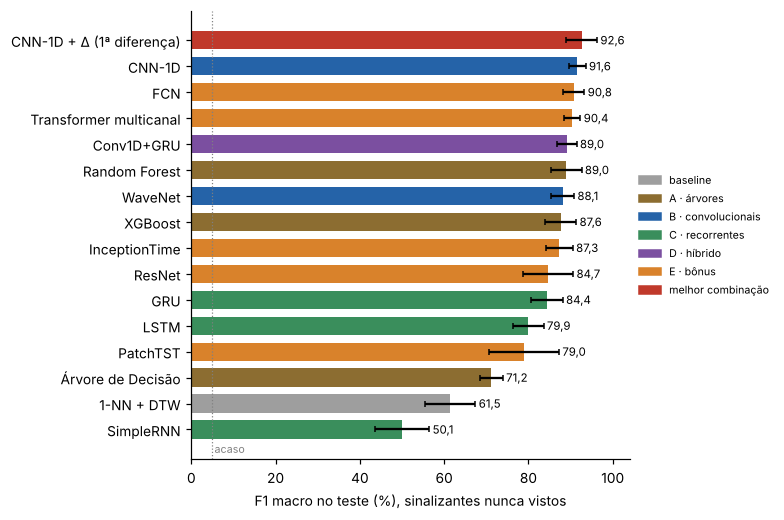

In [3]:
cores = {"Baseline": "#9e9e9e", "A": "#8c6d31", "B": "#2563A8", "C": "#3A8E5C", "D": "#7B4FA0", "Melhor": "#C0392B", "E": "#D9822B"}
def cor(g):
    return next(v for k, v in cores.items() if g.startswith(k))
ordem = geral[geral.modelo != "Classe majoritária"].copy()
ordem["rótulo"] = np.where(ordem.grupo == "Melhor combinação", "CNN-1D + Δ (1ª diferença)", ordem.modelo)
valores = {
    "1-NN + DTW": sel("1-NN + DTW").f1_macro, "Árvore de Decisão": sel("Árvore de Decisão", "lags").f1_macro,
    "Random Forest": sel("Random Forest", "lags").f1_macro, "XGBoost": sel("XGBoost", "lags").f1_macro,
    **{m: r03[r03.modelo == m].f1_macro for m in GRUPO}, "CNN-1D + Δ (1ª diferença)": d.f1_macro,
    **{m: r07[r07.modelo == m].f1_macro for m in ["Transformer multicanal", "PatchTST"]},
    **{m: r09a[r09a.modelo == m].f1_macro for m in ["FCN", "ResNet", "InceptionTime"]}}
ordem["média"] = [100 * valores[r].mean() for r in ordem["rótulo"]]
ordem["dp"] = [100 * valores[r].std() for r in ordem["rótulo"]]
ordem = ordem.sort_values("média")
fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.barh(ordem["rótulo"], ordem["média"], xerr=ordem["dp"], color=[cor(g) for g in ordem.grupo], capsize=2, height=0.7)
for yv, (m_, s_) in enumerate(zip(ordem["média"], ordem["dp"])):
    ax.text(m_ + s_ + 0.8, yv, f"{m_:.1f}".replace(".", ","), va="center", fontsize=7.5)
ax.axvline(5, ls=":", color="gray", lw=.8); ax.text(5.5, -0.9, "acaso", fontsize=7, color="gray")
ax.set_xlim(0, 104); ax.set_xlabel("F1 macro no teste (%), sinalizantes nunca vistos")
from matplotlib.patches import Patch
leg = [Patch(color=cores[k], label=l) for k, l in [("Baseline", "baseline"), ("A", "A · árvores"), ("B", "B · convolucionais"),
       ("C", "C · recorrentes"), ("D", "D · híbrido"), ("E", "E · bônus"), ("Melhor", "melhor combinação")]]
ax.legend(handles=leg, fontsize=7, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout(); plt.savefig(FIG / "08_tabela_geral.png", dpi=300, bbox_inches="tight"); plt.show()

## 2. Resumo do estudo de ablação

Ganho de F1 macro em relação ao sinal bruto (pontos percentuais), **pareado** por rodada e semente e testado com Wilcoxon. As técnicas do notebook 04 (média móvel, FFT e as duas) e do notebook 06 (1ª diferença) foram comparadas cada uma com o bruto da **mesma** execução.

Asteriscos: \* p < 0,05; \*\* p < 0,01; \*\*\* p < 0,001.

,MM (k=3),FFT (K=10),MM + FFT,Δ,X + Δ
Δ F1 (p.p.) vs bruto,,,,,
Random Forest,0.4,-0.1,0.1,-12.5***,0.2
CNN-1D,-0.2,-0.8,0.2,2.2*,1.5**
GRU,-5.5**,-0.5,-7.0***,-13.2***,-1.4
Conv1D+GRU,-0.6,-0.1,-1.9,-15.6***,-0.9


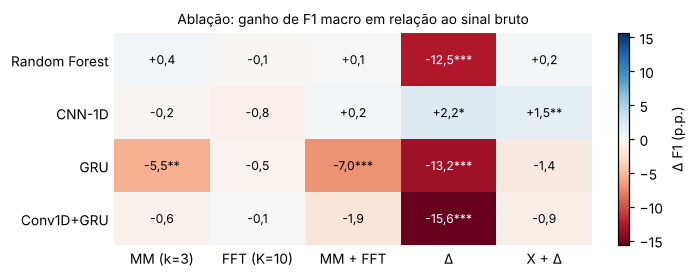

In [4]:
MODELOS = ["Random Forest", "CNN-1D", "GRU", "Conv1D+GRU"]
TEC = [("MM (k=3)", r04, "MM"), ("FFT (K=10)", r04, "FFT"), ("MM + FFT", r04, "Ambas"), ("Δ", r06d, "Δ"), ("X + Δ", r06d, "X + Δ")]
dados_abl, sig = pd.DataFrame(index=MODELOS, dtype=float), pd.DataFrame(index=MODELOS, dtype=object)
linhas = []
for modelo in MODELOS:
    for nome, df, tec in TEC:
        b = df[(df.modelo == modelo) & (df.tecnica == "bruto")].set_index(["rodada", "semente"]).f1_macro
        v = df[(df.modelo == modelo) & (df.tecnica == tec)].set_index(["rodada", "semente"]).f1_macro
        delta = (v - b.reindex(v.index)).dropna()
        p = wilcoxon(delta).pvalue if np.any(delta != 0) else 1.0
        dados_abl.loc[modelo, nome] = 100 * delta.mean()
        sig.loc[modelo, nome] = "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else ""
        linhas.append(dict(modelo=modelo, tecnica=nome, f1_bruto=100 * b.mean(), f1_tecnica=100 * v.mean(),
                           delta_pp=100 * delta.mean(), p_wilcoxon=p, pares_melhoraram=f"{int((delta > 0).sum())}/{len(delta)}"))
abl = pd.DataFrame(linhas)
abl.round(3).to_csv(RES / "08_resumo_ablacao.csv", index=False)
display((dados_abl.round(1).astype(str) + sig).rename_axis("Δ F1 (p.p.) vs bruto"))

fig, ax = plt.subplots(figsize=(6.4, 2.6))
lim = np.abs(dados_abl.values).max()
im = ax.imshow(dados_abl.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
for i in range(len(MODELOS)):
    for j in range(len(TEC)):
        ax.text(j, i, f"{dados_abl.iloc[i, j]:+.1f}".replace(".", ",") + sig.iloc[i, j], ha="center", va="center", fontsize=8,
                color="white" if abs(dados_abl.iloc[i, j]) > lim * 0.55 else "black")
ax.set_xticks(range(len(TEC)), [t[0] for t in TEC]); ax.set_yticks(range(len(MODELOS)), MODELOS)
ax.spines[:].set_visible(False); ax.tick_params(length=0)
plt.colorbar(im, ax=ax, label="Δ F1 (p.p.)", fraction=.04)
ax.set_title("Ablação: ganho de F1 macro em relação ao sinal bruto", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "08_ablacao.png", dpi=300, bbox_inches="tight"); plt.show()

## 3. Curva por horizonte (versão do artigo)

F1 macro em função da fração do sinal observada (notebook 05), para os modelos e estratégias que resumem o resultado: a CNN-1D (sem adaptação e direta), o Random Forest e a GRU (diretas).

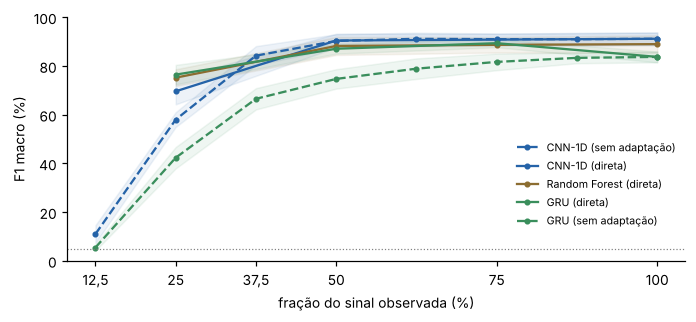

25%   50%   75%  100%
modelo        estrategia                           
CNN-1D        Direta         69.6  90.5  90.9  91.2
              Modelo único   69.9  89.7  89.5  90.0
              Sem adaptação  58.0  90.3  91.0  91.2
GRU           Direta         76.5  87.1  89.4  83.8
              Modelo único   68.8  86.0  86.1  77.6
              Sem adaptação  42.4  74.7  81.7  83.8
Random Forest Direta         75.3  88.3  88.7  89.0
WaveNet       Direta         67.6  85.7  88.0  87.6
              Modelo único   67.1  84.8  85.4  85.1
              Sem adaptação  55.9  84.2  87.4  87.6

In [5]:
r05["fracao"] = 100 * r05.h_avaliado / 32
curvas = [("CNN-1D", "Sem adaptação", "#2563A8", "--"), ("CNN-1D", "Direta", "#2563A8", "-"),
          ("Random Forest", "Direta", "#8c6d31", "-"), ("GRU", "Direta", "#3A8E5C", "-"), ("GRU", "Sem adaptação", "#3A8E5C", "--")]
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for modelo, est, c, ls in curvas:
    g = r05[(r05.modelo == modelo) & (r05.estrategia == est)].groupby("fracao").f1_macro.agg(["mean", "std"])
    ax.plot(g.index, 100 * g["mean"], ls, marker="o", ms=3, color=c, label=f"{modelo} ({est.lower()})")
    ax.fill_between(g.index, 100 * (g["mean"] - g["std"]), 100 * (g["mean"] + g["std"]), color=c, alpha=.08)
ax.axhline(5, ls=":", color="gray", lw=.8)
ax.set_xticks([12.5, 25, 37.5, 50, 75, 100], ["12,5", "25", "37,5", "50", "75", "100"])
ax.set_xlabel("fração do sinal observada (%)"); ax.set_ylabel("F1 macro (%)"); ax.set_ylim(0, 100)
ax.legend(fontsize=7, loc="lower right", bbox_to_anchor=(1.0, 0.1), frameon=False)
plt.tight_layout(); plt.savefig(FIG / "08_horizonte.png", dpi=300, bbox_inches="tight"); plt.show()

tab_h = (r05[r05.h_avaliado.isin([8, 16, 24, 32])].groupby(["modelo", "estrategia", "h_avaliado"]).f1_macro.mean()
         .unstack().mul(100).round(1))
tab_h.columns = ["25%", "50%", "75%", "100%"]
display(tab_h)
tab_h.to_csv(RES / "08_tabela_horizonte.csv")

## 4. Tabelas em LaTeX (modelo da SBC)

Prontas para colar no artigo (pacote `booktabs`).

In [6]:
def para_latex(df, legenda, rotulo, colunas):
    import re
    def celula(x):
        x = re.sub(r"(\d)\.(\d)", r"\1{,}\2", str(x))            # vírgula decimal (português)
        return x.replace("±", r"$\pm$").replace("%", r"\%").replace("Δ", r"$\Delta$").replace("·", r"--")
    corpo = "\n".join(" & ".join(celula(x) for x in linha) + r" \\" for linha in df[colunas].itertuples(index=False))
    cab = " & ".join(c.replace("Δ", r"$\Delta$") for c in colunas) + r" \\"
    return (r"\begin{table}[t]" "\n" r"\centering\footnotesize" "\n" rf"\caption{{{legenda}}}\label{{{rotulo}}}" "\n"
            rf"\begin{{tabular}}{{{'l' * 2 + 'c' * (len(colunas) - 2)}}}" "\n" r"\toprule" "\n" + cab + "\n" r"\midrule" "\n"
            + corpo + "\n" r"\bottomrule" "\n" r"\end{tabular}" "\n" r"\end{table}")

tg = geral.drop(columns="_ordem").copy()
tg["modelo"] = np.where(tg.grupo == "Melhor combinação", "CNN-1D + $\\Delta$", tg.modelo)
tex_geral = para_latex(tg.rename(columns={"F1 macro (%)": "F1 (\\%)", "acurácia balanceada (%)": "Acc. bal. (\\%)", "F1 calibrada (%)": "F1 calib. (\\%)"}),
                       "Desempenho no teste com sinalizantes nunca vistos (média $\\pm$ desvio, 4 rodadas $\\times$ 3 sementes).",
                       "tab:geral", ["grupo", "modelo", "F1 (\\%)", "Acc. bal. (\\%)", "F1 calib. (\\%)"])
ta = (dados_abl.round(1).map(lambda v: f"{v:+.1f}") + sig).reset_index().rename(columns={"index": "modelo"})
ta.insert(1, "bruto", [f"{100 * r04[(r04.modelo == m) & (r04.tecnica == 'bruto')].f1_macro.mean():.1f}" for m in MODELOS])
tex_abl = para_latex(ta, "Ablação: $\\Delta$F1 (p.p.) de cada técnica em relação ao sinal bruto (Wilcoxon pareado: * $p<0{,}05$, ** $p<0{,}01$, *** $p<0{,}001$).",
                     "tab:ablacao", list(ta.columns))
(RES / "08_tabela_geral.tex").write_text(tex_geral, encoding="utf-8")
(RES / "08_tabela_ablacao.tex").write_text(tex_abl, encoding="utf-8")
print(tex_geral); print(); print(tex_abl)

\begin{table}[t]
\centering\footnotesize
\caption{Desempenho no teste com sinalizantes nunca vistos (média $\pm$ desvio, 4 rodadas $\times$ 3 sementes).}\label{tab:geral}
\begin{tabular}{llccc}
\toprule
grupo & modelo & F1 (\%) & Acc. bal. (\%) & F1 calib. (\%) \\
\midrule
Baseline ingênua & Classe majoritária & 0{,}5 $\pm$ 0{,}0 & 5{,}0 & — \\
Baseline clássica & 1-NN + DTW & 61{,}5 $\pm$ 6{,}0 & 61{,}8 & — \\
A1 -- Tabular & Árvore de Decisão & 71{,}2 $\pm$ 2{,}7 & 72{,}2 & — \\
A2 -- Tabular & Random Forest & 89{,}0 $\pm$ 3{,}6 & 89{,}8 & — \\
A2 -- Tabular & XGBoost & 87{,}6 $\pm$ 3{,}7 & 88{,}1 & — \\
B1 -- Convolucional & CNN-1D & 91{,}6 $\pm$ 2{,}0 & 92{,}0 & 91{,}1 $\pm$ 2{,}2 \\
B2 -- Convolucional & WaveNet & 88{,}1 $\pm$ 2{,}7 & 88{,}7 & 87{,}9 $\pm$ 2{,}5 \\
C1 -- Recorrente & SimpleRNN & 50{,}1 $\pm$ 6{,}4 & 51{,}5 & 53{,}9 $\pm$ 4{,}6 \\
C2 -- Recorrente & LSTM & 79{,}9 $\pm$ 3{,}7 & 80{,}9 & 78{,}0 $\pm$ 3{,}8 \\
C3 -- Recorrente & GRU & 84{,}4 $\pm$ 3{,}7 & 85{,}1 & 83{

## 5. Respostas às questões de pesquisa

**Q1. Qual família de modelos generaliza melhor para sinalizantes que não estavam no treino?** As **convolucionais**. A CNN-1D é o melhor modelo com o sinal bruto (91,6%), seguida da híbrida Conv1D+GRU (89,0%) e do Random Forest sobre a janela de *lags* (89,0%). As recorrentes ficam abaixo (GRU 84,4%, LSTM 79,9%) e a SimpleRNN fracassa (50,1%). A calibração de hiperparâmetros não muda essa ordem. Nenhuma arquitetura mais complexa do bônus supera a CNN-1D. Entre os Transformers com patches, o multicanal empata (90,4%) e o PatchTST, com canais independentes, perde 11,8 pontos. Entre as CNNs de referência em classificação de séries, a FCN empata (90,8% contra 90,5% na mesma execução, p = 0,91) com 3 vezes mais parâmetros, e as mais profundas perdem de forma significativa (ResNet −5,8 e InceptionTime −3,2 pontos, p = 0,009): com ~670 vídeos de treino, a profundidade decora os sinalizantes de treino.

**Q2. O pré-processamento melhora o resultado?** As técnicas de **suavização** (média móvel, FFT) **não** melhoram nenhum modelo, e a decomposição piora a GRU: o ruído do MediaPipe não é o gargalo. A **1ª diferença** (velocidades) é a única técnica com ganho consistente, e só na CNN-1D (+2,2 pontos, p = 0,034, levando ao melhor resultado do trabalho, **92,6%**): ela remove o deslocamento próprio de cada pessoa, que é a principal fonte de erro com sinalizantes novos. O **aumento de dados** (deformação do tempo, escala, deformação de amplitude) também não ajuda a CNN-1D + Δ (−0,2 a −1,4 pontos, sem significância): a reamostragem para 32 instantes e a normalização pelos ombros já removem a duração e a escala que essas transformações simulam.

**Q3. Quão cedo dá para reconhecer o sinal?** Com **50% do trecho ativo** (~1,5 s), a CNN-1D já tem ~90% de F1, praticamente o mesmo que com o sinal inteiro. Abaixo disso, a queda é rápida (58–70% com 25%). Treinar um modelo para cada horizonte (estratégia direta) só compensa nos horizontes curtos. Os mapas de ativação (CAM, notebook 09) explicam o resultado: a evidência da CNN-1D está no núcleo do gesto (instantes ~8 a 24 de 32) e na **forma da mão dominante** (1,6 vez a relevância média por canal). A preparação e a retração quase não contam, então metade do sinal já cobre boa parte do núcleo.